In [1]:
import numpy as np
from pathlib import Path
import timeit
import pandas as pd
import sys
sys.path.insert(1, '../')
import util
from util.dynamics import temp_response, environmental_update
from util.plot import lighten_color,Radar
from util.overshoots import local_safety, critical_parameter

import scipy as sp
import matplotlib.pyplot as plt
# import tqdm
from matplotlib.lines import Line2D

import tqdm
import seaborn as sns
from scipy.optimize import fsolve
import os
from scipy.optimize import curve_fit

import matplotlib as mpl
import xarray as xr
from matplotlib.projections import PolarAxes

# Loading in data

## Using PROVIDE Project scenarios
Robin Lamboll, Joeri Rogelj, & Carl-Friedrich Schleussner. (2025). Scenario emissions and temperature data for PROVIDE project (v1.3.0) [Data set]. Zenodo. https://doi.org/10.5281/zenodo.11108741

https://pure.iiasa.ac.at/id/eprint/18130/1/essoar.10511875.2.pdf for description

https://zenodo.org/records/11108741 for actual data set

In [2]:
folder = '../../Data/PROVIDE 2025/'
cols = list(pd.read_csv(folder+'post-2100_inc_redundanttier1_temperature_summary.csv',nrows=1))
df = pd.read_csv(folder+'post-2100_inc_redundanttier1_temperature_summary.csv',
                 usecols = [c for c in cols if (c != 'quantile') and (c!= 'atomic_scen')]).set_index('scenario').T
df.index.names=['year']
# df=df.rename(columns={'scenario':''})
scenarios = df.columns.values

## GTPR2025 Tipping elements

In [4]:
df_TEs = pd.read_excel('../../Data/TEsummary.xlsx',header=[0],index_col=0,sheet_name='GTPR25')
df_TEs[['Threshold (°C) – Min.', 
        'Threshold (°C) – Est.', 
        'Threshold (°C) – Max.']] = df_TEs[['Threshold (°C) – Min.', 
                                            'Threshold (°C) – Est.', 
                                            'Threshold (°C) – Max.']].interpolate(method='linear', axis=1, limit_direction='backward')
T_lim = df_TEs['Threshold (°C) – Est.'].to_numpy() # Critical threshold for tipping
betas = df_TEs['Beta (1/°C)'].to_numpy() # Logistic parameter (temp. sensitivity)
q_c = 1/(1+df_TEs['Collapse (years)'].to_numpy()) # collapse leverage
q_r = 1/(1+df_TEs['Recovery (years)'].to_numpy())

# Loading pre-saved interaction matrices
len_sample=500
A = [np.loadtxt('../../Data/Interaction matrices/A_%s.csv'%r) for r in range(len_sample)]

# Simulations

In [6]:
# -------- SIMULATIONS --------------
years = np.arange(1850,2301)
no_years = len(years)

# Modifying collapse probabilities for each year according to each scenario
p_c = np.ones((len(scenarios),no_years,len(df_TEs)))
p_c *= q_c

p_r = np.ones((len(scenarios),no_years,len(df_TEs)))
p_r *= q_r

for t in range(no_years):
    for i,s in enumerate(scenarios):
        p_c[i,t,:] *= temp_response(df[s].to_numpy()[t], T_lim, betas)
        p_r[i,t,:] *= (1-temp_response(df[s].to_numpy()[t], T_lim, betas))

D = np.zeros((len(scenarios),len_sample,len(df_TEs),no_years))
for r in tqdm.tqdm(range(len_sample)):
    for j in range(len(scenarios)):
        for t in range(1,no_years):
            D[j,r,:,t] = environmental_update(D[j,r,:,t-1],A[r],pc=p_c[j,t,:],pr=p_r[j,t,:])

100%|█████████████████████████████████████████| 500/500 [00:19<00:00, 25.37it/s]


# plotting

In [20]:
D.shape

(15, 500, 9, 451)

In [21]:
year_axis=-1
sample_axis=1
D_max = np.max(D,axis=year_axis,keepdims=True).mean(axis=sample_axis,keepdims=True).reshape(15,9)

In [22]:
D_max.shape

(15, 9)

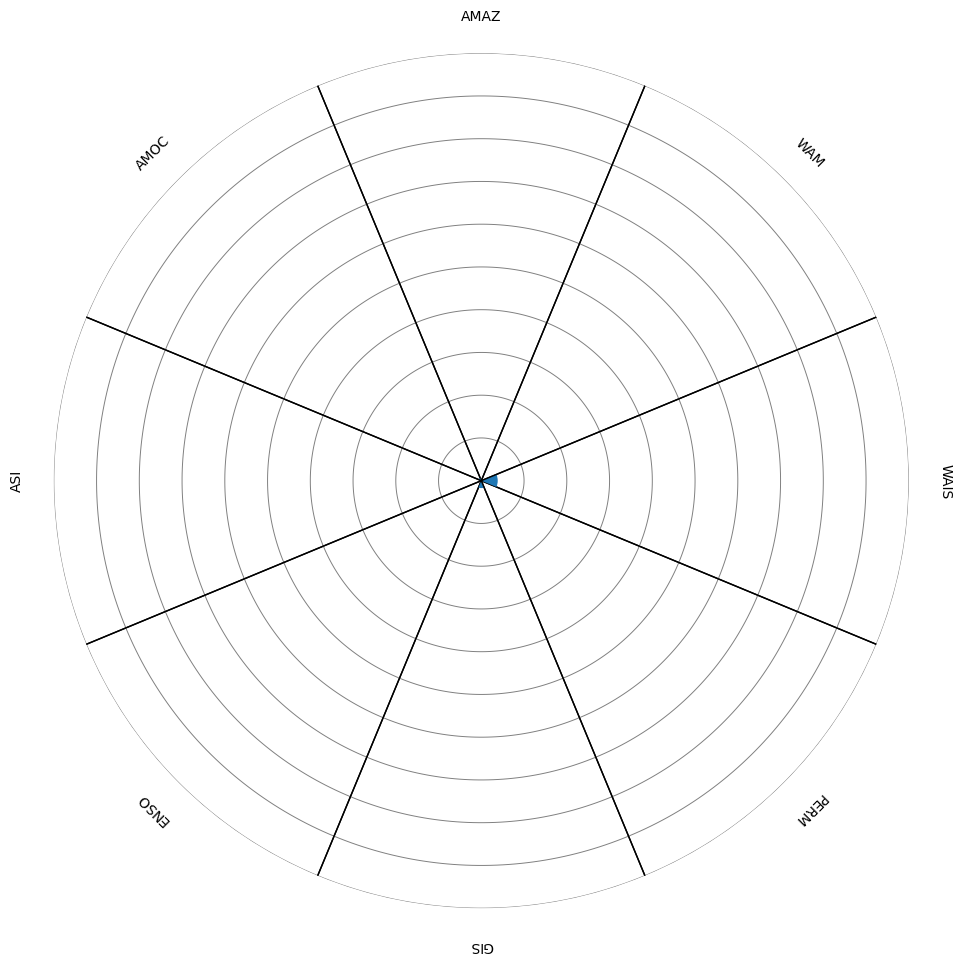

In [35]:
to_del=6
D_plot = np.delete(D_max, to_del, axis=1)*100
titles = list(np.delete(df_TEs.index.values, to_del ,axis=0))
N=len(titles)

rticks = [np.arange(0,101,step=10)]*N
ylims=[(0,100)]*N

outer_width = 360/N
inner_width = 180/3/N
width = outer_width+inner_width

fig=plt.figure(figsize=(9,9))
radar = Radar(fig, titles, rotate_labels=True, 
              wedge_width = outer_width, with_rlabels=False, 
              ylims=ylims, rticks=rticks)

radar.bar(D_plot[7,:],width=np.deg2rad(outer_width))

In [14]:
print(local_safety(D[0,:,:,:],dimension_kw=dict(year=-1,sample=0)))

[[[False]
  [False]
  [ True]
  [ True]
  [ True]
  [ True]
  [False]
  [False]
  [False]]]


In [12]:
print(local_safety)

<function local_safety at 0x79b229cc1260>
